In [61]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


 IMPORTACION DE LIBRERIAS -->


In [62]:
import pandas as pd
import numpy as np
import seaborn as sn
import altair as alt
import matplotlib.pyplot as plt
data = pd.read_excel("/content/drive/MyDrive/DATOS_limpio.xlsx")
%matplotlib inline
df = pd.read_excel("/content/drive/MyDrive/DATOS_limpio.xlsx")

 TAMAÑO DE CONJUNTO DE DATOS -->

In [63]:
print(df.head())
print(df.shape)

         Sus1      CAS PM(g/mol) pf(°C) P.eb(°C) Densidad(g/cm3)    pKa  \
0  Metilamina  74-89-5     31.06  -93.5     -6.3       0,66_(25)  10.63   
1  Metilamina  74-89-5     31.06  -93.5     -5.3       0,66_(25)  10.63   
2  Metilamina  74-89-5     31.06  -93.5     -4.3       0,66_(25)  10.63   
3  Metilamina  74-89-5     31.06  -93.5     -3.3       0,66_(25)  10.63   
4  Metilamina  74-89-5     31.06  -93.5     -2.3       0,66_(25)  10.63   

  Momento_dipolar S(g/L)     Pv(Pas)  ... Pro3 CAS(PRO)3 PM6(g/mol) Pf6(°C)  \
0            1.31   1030  3,36_x_10⁵  ...  NaN       NaN        NaN     NaN   
1            1.31   1030  3,36_x_10⁵  ...  NaN       NaN        NaN     NaN   
2            1.31   1030  3,36_x_10⁵  ...  NaN       NaN        NaN     NaN   
3            1.31   1030  3,36_x_10⁵  ...  NaN       NaN        NaN     NaN   
4            1.31   1030  3,36_x_10⁵  ...  NaN       NaN        NaN     NaN   

  P.eb6(°C) Densidad6(g/cm3) pKa6 Momento_dipolar6  S6 Pv6  
0       NaN  

 DEFINICION DE COMPUESTOS -->

In [64]:
compounds = ["Metilamina", "Bencidina", "N-isopropil-N-metilpropan-2amina", "AzometinaN-metiletanamina", "Dimetilamina", "Trimetilamina", "Acetamida", "N-metilacetamida", "N,N-dimetilacetamida", "Urea", "N-metiletanamina"]

 FILTRACION DE DATOS -->

In [65]:
filtered = df[df["Sus1"].isin(compounds)]

In [66]:
print(filtered["Sus1"].value_counts())
print(f"Kept {len(filtered)} of {len(df)} rows")

Sus1
Metilamina                          12
Trimetilamina                       11
N-metiletanamina                    11
Bencidina                           11
Dimetilamina                        10
N-isopropil-N-metilpropan-2amina    10
Acetamida                           10
N-metilacetamida                    10
N,N-dimetilacetamida                10
Urea                                10
Name: count, dtype: int64
Kept 105 of 200 rows


In [67]:
filtered.to_csv("filtered_compounds.csv")

In [68]:
df = pd.read_csv("filtered_compounds.csv")

In [69]:
params = df.select_dtypes(include="number")
params.head()

,Unnamed: 0,PM(g/mol),pf(°C),S2(g/L),PM3(g/mol),pf3(°C),Densidad3(g/cm3),pKa3,Momento_dipolar3,S3(g/L),...,Pro3,CAS(PRO)3,PM6(g/mol),Pf6(°C),P.eb6(°C),Densidad6(g/cm3),pKa6,Momento_dipolar6,S6,Pv6
0,0,31.06,-93.5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,31.06,-93.5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2,31.06,-93.5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3,31.06,-93.5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,4,31.06,-93.5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [70]:
params = df[["PM(g/mol)", "pf(°C)", "P.eb(°C)", "Densidad(g/cm3)", "pKa", "Momento_dipolar", "S(g/L)"]]

In [71]:
import pandas as pd
import numpy as np

# Creamos una copia para limpiar los datos sin alterar el original de forma destructiva
params_clean = params.copy()

for col in params_clean.columns:
    # Convertimos a string para aplicar operaciones de texto
    params_clean[col] = params_clean[col].astype(str)
    # Reemplazamos comas decimales por puntos
    params_clean[col] = params_clean[col].str.replace(',', '.', regex=False)
    # Extraemos el primer número decimal o entero que aparezca en el texto
    params_clean[col] = params_clean[col].str.extract(r'([-+]?\d*\.?\d+)')
    # Convertimos a tipo de dato float numérico
    params_clean[col] = pd.to_numeric(params_clean[col], errors='coerce')

# Calculamos la correlación de Spearman sobre los datos limpios
corr = params_clean.corr(method="spearman")

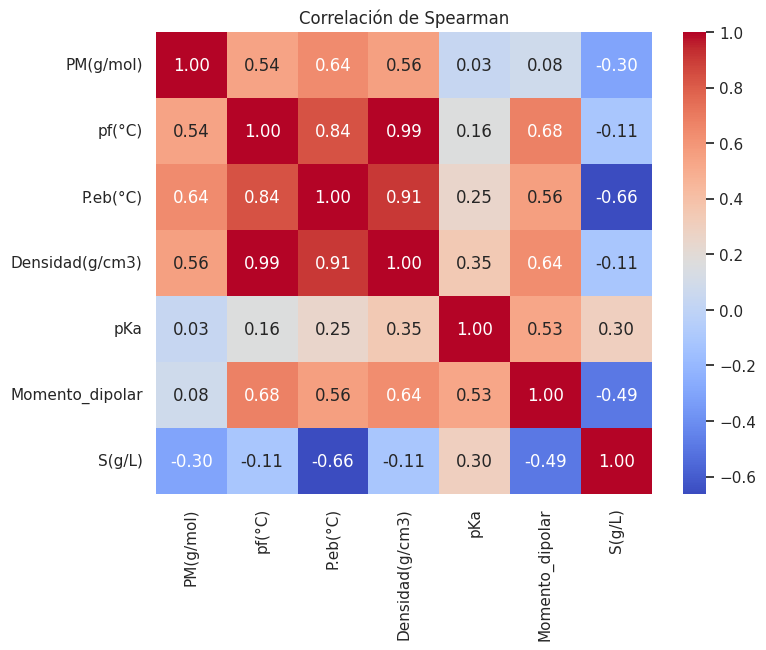

In [72]:
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlación de Spearman")
plt.show()

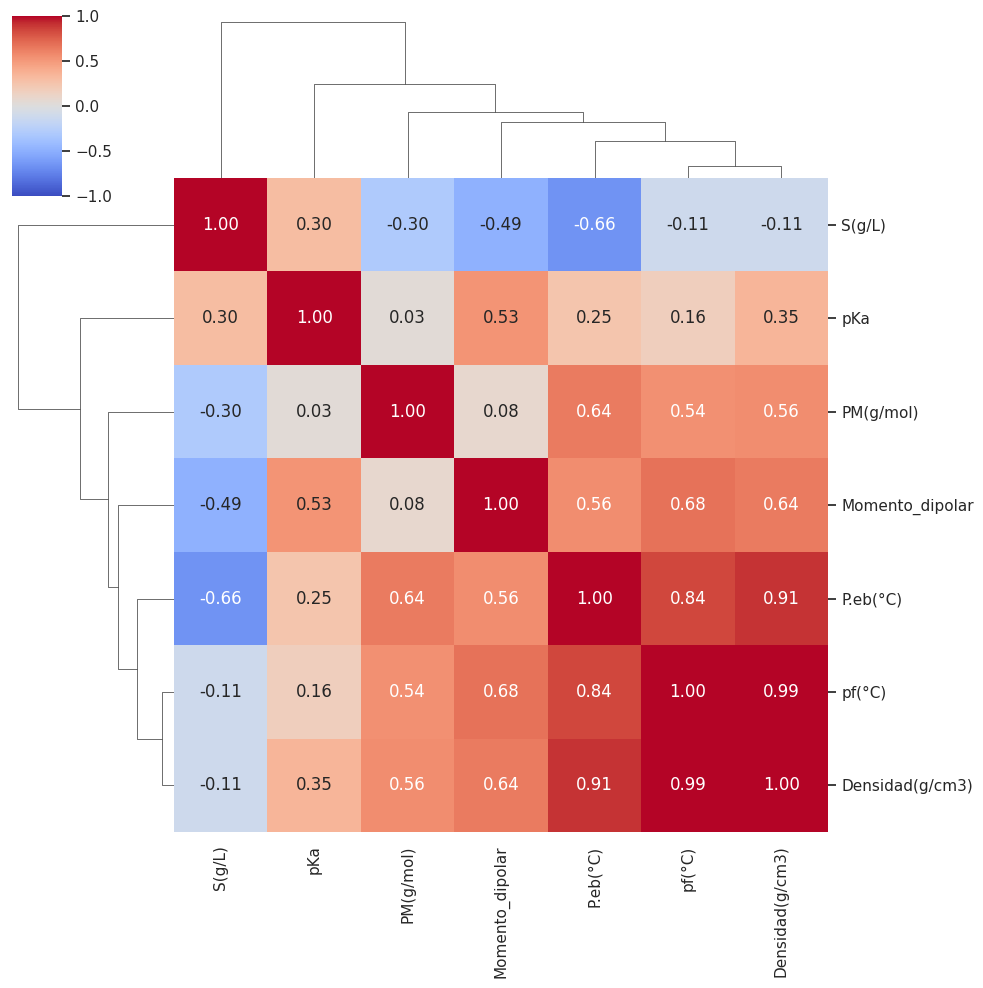

In [73]:
sns.clustermap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1,
vmax=1)
plt.show()

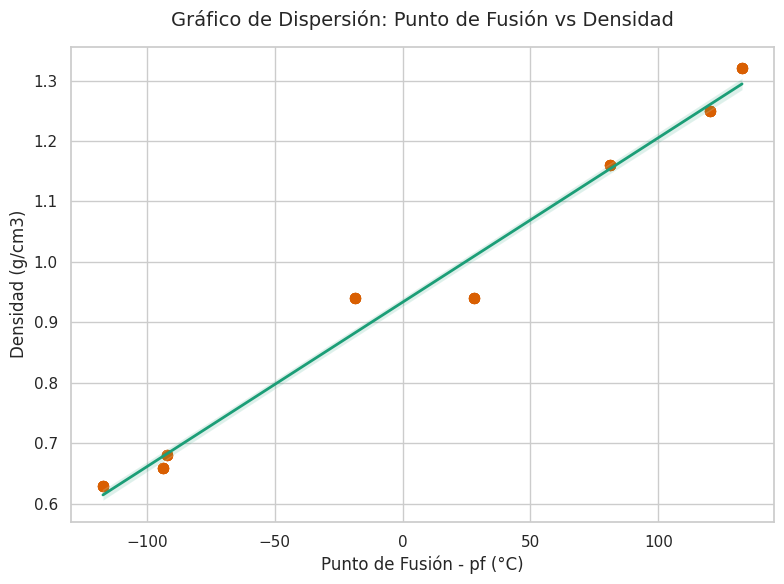

In [74]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configuramos el estilo del gráfico
sns.set_theme(style="whitegrid")

# Creamos el gráfico de dispersión con una línea de regresión
plt.figure(figsize=(8, 6))
sns.regplot(
    data=params_clean,
    x='pf(°C)',
    y='Densidad(g/cm3)',
    scatter_kws={'alpha':0.6, 'color': '#d95f02', 's': 50},
    line_kws={'color': '#1b9e77', 'linewidth': 2}
)

# Añadimos títulos y etiquetas personalizadas
plt.title('Gráfico de Dispersión: Punto de Fusión vs Densidad', fontsize=14, pad=15)
plt.xlabel('Punto de Fusión - pf (°C)', fontsize=12)
plt.ylabel('Densidad (g/cm3)', fontsize=12)

# Ajustamos el diseño
plt.tight_layout()
plt.show()

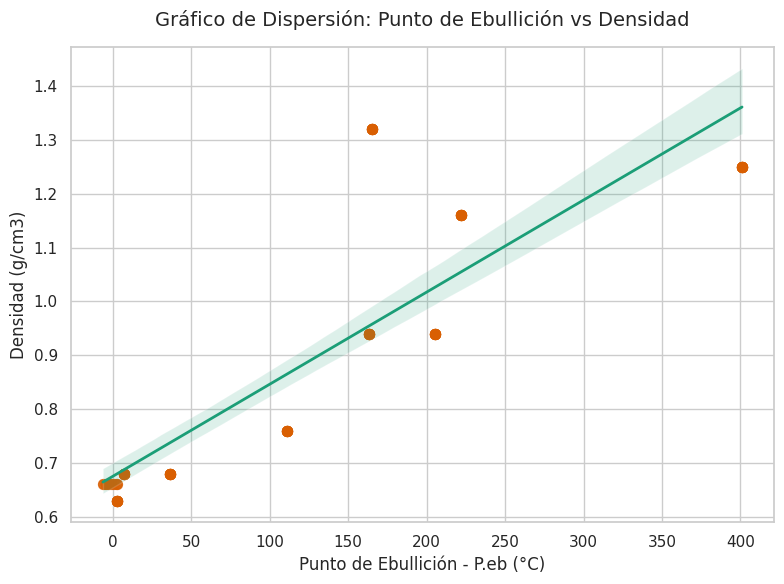

In [75]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configuramos el estilo estético del gráfico
sns.set_theme(style="whitegrid")

# Creamos el gráfico de dispersión con línea de regresión para P.eb vs Densidad
plt.figure(figsize=(8, 6))
sns.regplot(
    data=params_clean,
    x='P.eb(°C)',
    y='Densidad(g/cm3)',
    scatter_kws={'alpha':0.6, 'color': '#d95f02', 's': 50},
    line_kws={'color': '#1b9e77', 'linewidth': 2}
)

# Añadimos etiquetas y título
plt.title('Gráfico de Dispersión: Punto de Ebullición vs Densidad', fontsize=14, pad=15)
plt.xlabel('Punto de Ebullición - P.eb (°C)', fontsize=12)
plt.ylabel('Densidad (g/cm3)', fontsize=12)

# Ajustamos el espaciado
plt.tight_layout()
plt.show()

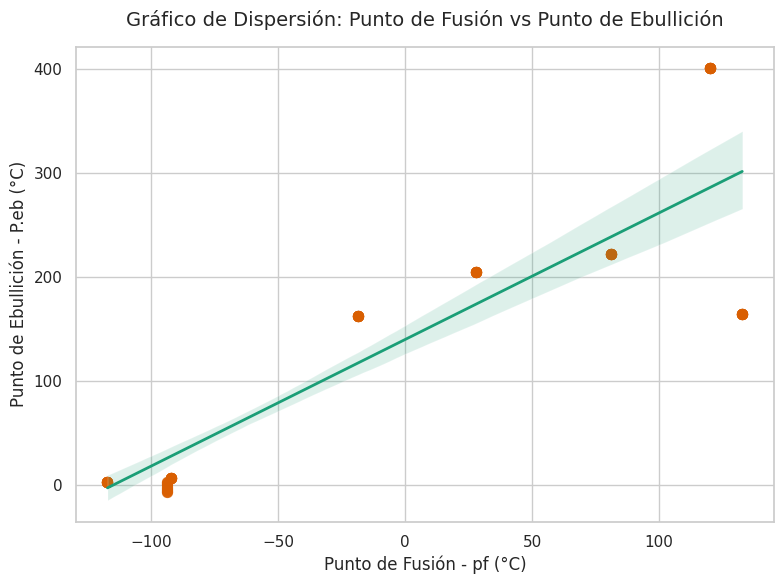

In [76]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configuramos el estilo estético del gráfico
sns.set_theme(style="whitegrid")

# Creamos el gráfico de dispersión con línea de regresión para pf vs P.eb
plt.figure(figsize=(8, 6))
sns.regplot(
    data=params_clean,
    x='pf(°C)',
    y='P.eb(°C)',
    scatter_kws={'alpha':0.6, 'color': '#d95f02', 's': 50},
    line_kws={'color': '#1b9e77', 'linewidth': 2}
)

# Añadimos etiquetas y título
plt.title('Gráfico de Dispersión: Punto de Fusión vs Punto de Ebullición', fontsize=14, pad=15)
plt.xlabel('Punto de Fusión - pf (°C)', fontsize=12)
plt.ylabel('Punto de Ebullición - P.eb (°C)', fontsize=12)

# Ajustamos el espaciado
plt.tight_layout()
plt.show()

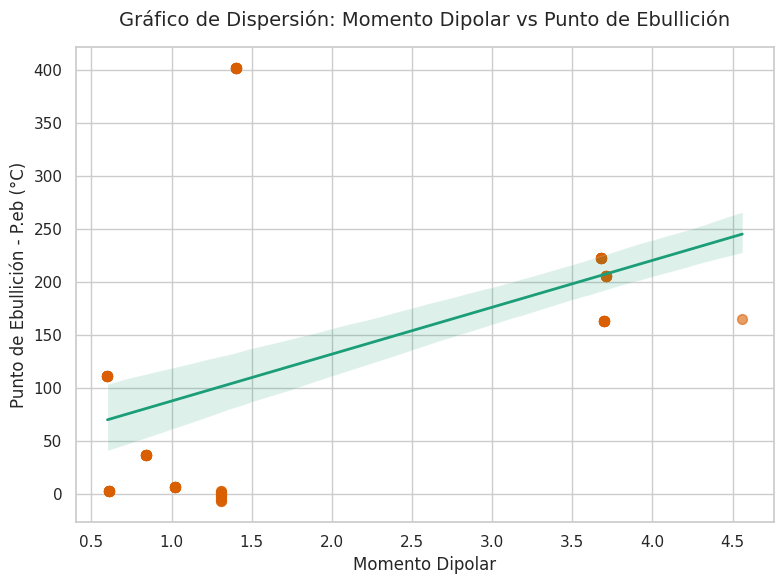

In [77]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configuramos el estilo estético del gráfico
sns.set_theme(style="whitegrid")

# Creamos el gráfico de dispersión con línea de regresión para Momento_dipolar vs P.eb
plt.figure(figsize=(8, 6))
sns.regplot(
    data=params_clean,
    x='Momento_dipolar',
    y='P.eb(°C)',
    scatter_kws={'alpha':0.6, 'color': '#d95f02', 's': 50},
    line_kws={'color': '#1b9e77', 'linewidth': 2}
)

# Añadimos etiquetas y título
plt.title('Gráfico de Dispersión: Momento Dipolar vs Punto de Ebullición', fontsize=14, pad=15)
plt.xlabel('Momento Dipolar', fontsize=12)
plt.ylabel('Punto de Ebullición - P.eb (°C)', fontsize=12)

# Ajustamos el espaciado
plt.tight_layout()
plt.show()

In [78]:
# Filtramos el DataFrame conservando únicamente las columnas 'Tipo_reacción' y 'Medio'
df_filtrado = df[['Tipo_reaccion', 'Medio']]

# Mostramos las primeras filas del resultado
display(df_filtrado.head(10))

,Tipo_reaccion,Medio
0,Condensación,Apolar
1,SN,Básico
2,Redox,Neutro
3,SN,Neutro
4,Redox,Básico
5,SN,Apolar
6,AN,Ácido
7,SN,Neutro
8,Redox,Neutro
9,SN,Neutro


In [79]:
df_freq_medio = FrecuenciaMedio.reset_index()
df_freq_medio.columns = ['Valor', 'Frecuencia']
df_freq_medio['Variable'] = 'Medio'

df_freq_tipo = FrecuenciaTipo_reaccion.reset_index()
df_freq_tipo.columns = ['Valor', 'Frecuencia']
df_freq_tipo['Variable'] = 'Tipo de reacción'
df_plot = pd.concat([df_freq_medio, df_freq_tipo])

chart = (
    alt.Chart(df_plot)
    .mark_bar()
    .encode(
        x=alt.X('Valor:N', title='Categoría', axis=alt.Axis(labelAngle=0)),
        y=alt.Y('Frecuencia:Q', title='Frecuencia'),
                color=alt.Color('Variable:N', title='Variable/Atributo', scale=alt.Scale(scheme='tableau10')),
        xOffset='Variable:N',
        tooltip=['Variable', 'Valor', 'Frecuencia']
    )
    .properties(
        title='Comparativa de Frecuencias: Medio vs Tipo de reacción',
        width=550,
        height=350
    )
    .interactive()
)

chart.display()

alt.Chart(...)

In [80]:
Datos = df_filtrado.Medio, df_filtrado.Tipo_reaccion
FrecuenciaMedio = df_filtrado.Medio.value_counts()
FrecuenciaTipo_reaccion = df_filtrado.Tipo_reaccion.value_counts()

print('Datos')
print(df_filtrado)
print('Frecuencia de los datos')
print(FrecuenciaMedio)
print(FrecuenciaTipo_reaccion)

df_freq_medio = FrecuenciaMedio.reset_index()
df_freq_medio.columns = ['Valor', 'Frecuencia']
df_freq_medio['Variable'] = 'Medio'

df_freq_tipo = FrecuenciaTipo_reaccion.reset_index()
df_freq_tipo.columns = ['Valor', 'Frecuencia']
df_freq_tipo['Variable'] = 'Tipo de reacción'

df_plot = pd.concat([df_freq_medio, df_freq_tipo])

chart = (
    alt.Chart(df_plot)
    .mark_bar()
    .encode(
        x=alt.X('Valor:N', title='Categoría', sort='-y'),
        y=alt.Y('Frecuencia:Q', title='Frecuencia'),
        color=alt.Color('Variable:N', title='Variable/Atributo', scale=alt.Scale(scheme='tableau10')),
        xOffset='Variable:N',
        tooltip=['Variable', 'Valor', 'Frecuencia']
    )
    .properties(
        title='Comparativa de Frecuencias: Medio vs Tipo de reacción',
        width=500,
        height=350
    )
    .interactive()
)
chart.display()

Datos
    Tipo_reaccion   Medio
0    Condensación  Apolar
1              SN  Básico
2           Redox  Neutro
3              SN  Neutro
4           Redox  Básico
..            ...     ...
100  Condensación     NaN
101            SN     NaN
102  Condensación     NaN
103  Condensación     NaN
104  Condensación     NaN

[105 rows x 2 columns]
Frecuencia de los datos
Medio
Neutro    5
Apolar    2
Básico    2
Ácido     2
Name: count, dtype: int64
Tipo_reaccion
SN              55
Condensación    16
AN              12
Redox            7
SR               7
SE               5
AR               2
AE               1
Name: count, dtype: int64


alt.Chart(...)

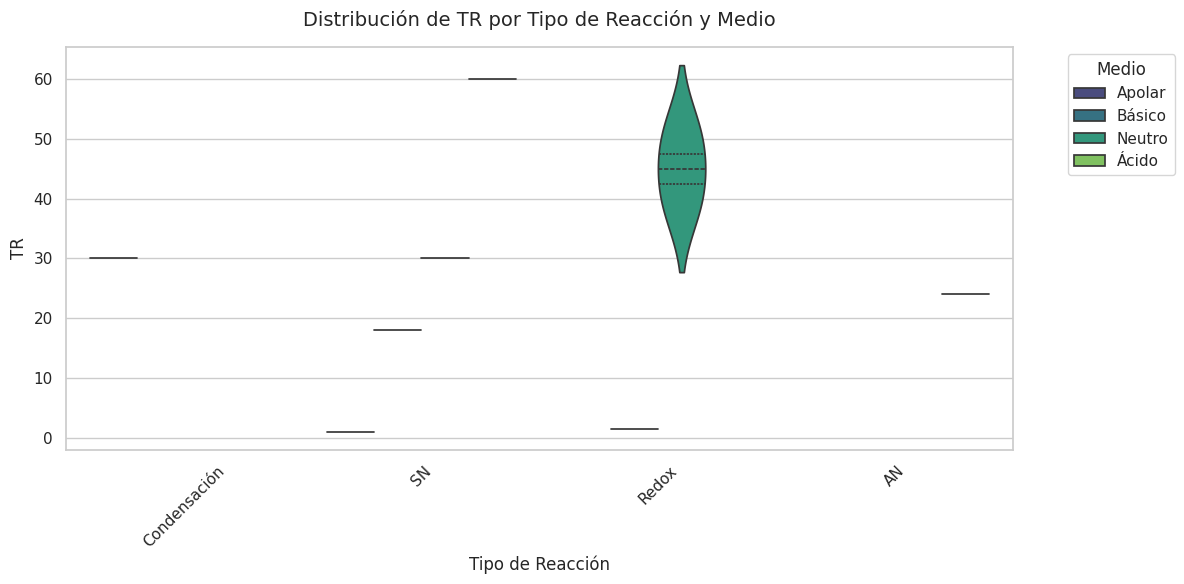

In [81]:
sns.set_theme(style="whitegrid")

df_violin = df_filtrado.copy()

if 'TR' in df.columns:
    df_violin['TR'] = df['TR']
else:
    tr_col = [col for col in df.columns if col.upper() == 'TR']
    if tr_col:
        df_violin['TR'] = df[tr_col[0]]
    else:
        df_violin['TR'] = np.nan

df_violin['TR'] = df_violin['TR'].astype(str)
df_violin['TR'] = df_violin['TR'].str.replace(',', '.', regex=False)
df_violin['TR'] = df_violin['TR'].str.extract(r'([-+]?\d*\.?\d+)')
df_violin['TR'] = pd.to_numeric(df_violin['TR'], errors='coerce')


df_violin = df_violin.dropna(subset=['Tipo_reaccion', 'Medio', 'TR'])


plt.figure(figsize=(12, 6))
sns.violinplot(
    data=df_violin,
    x='Tipo_reaccion',
    y='TR',
    hue='Medio',
    palette='viridis',
    inner='quartile'
)


plt.title('Distribución de TR por Tipo de Reacción y Medio', fontsize=14, pad=15)
plt.xlabel('Tipo de Reacción', fontsize=12)
plt.ylabel('TR', fontsize=12)
plt.xticks(rotation=45)
plt.legend(title='Medio', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

<Figure size 1400x700 with 0 Axes>

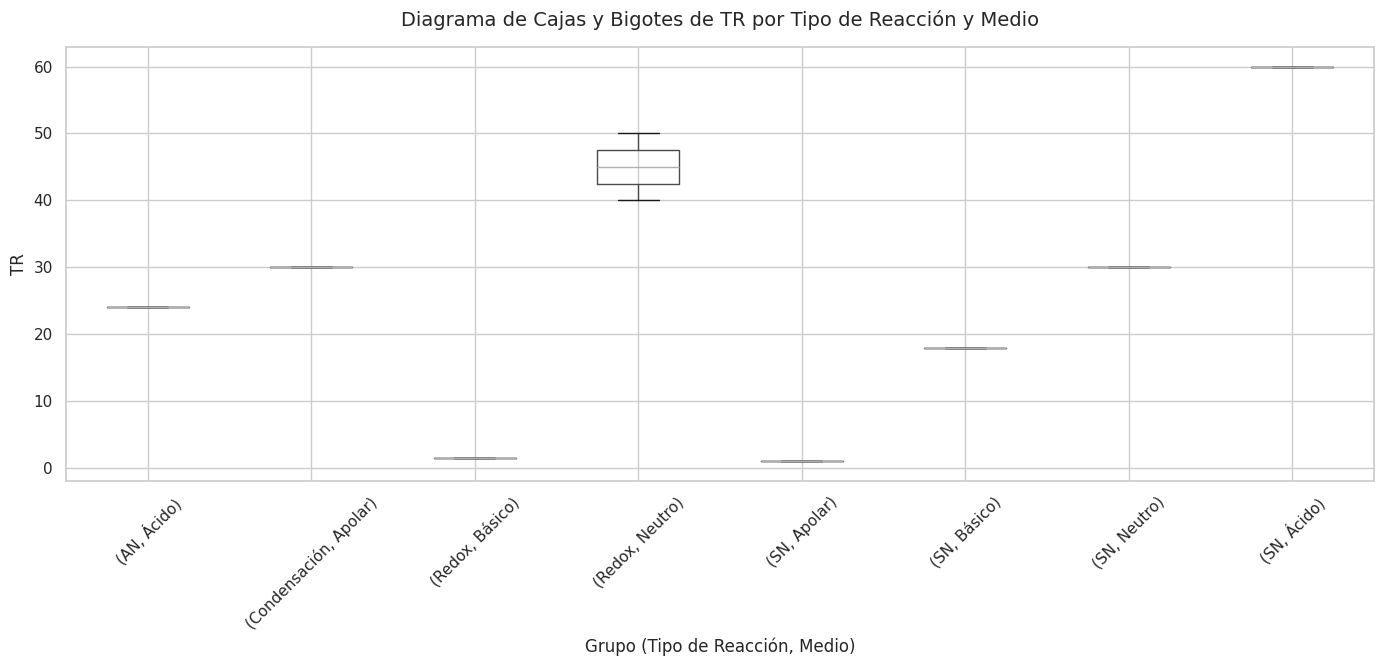

In [82]:
df_boxplot = df_filtrado.copy()

if 'TR' in df.columns:
    df_boxplot['TR'] = df['TR']
else:
    tr_col = [col for col in df.columns if col.upper() == 'TR']
    if tr_col:
        df_boxplot['TR'] = df[tr_col[0]]
    else:
        df_boxplot['TR'] = np.nan

df_boxplot['TR'] = df_boxplot['TR'].astype(str).str.replace(',', '.', regex=False)
df_boxplot['TR'] = df_boxplot['TR'].str.extract(r'([-+]?\d*\.?\d+)')
df_boxplot['TR'] = pd.to_numeric(df_boxplot['TR'], errors='coerce')

df_boxplot = df_boxplot.dropna(subset=['Tipo_reaccion', 'Medio', 'TR'])

plt.figure(figsize=(14, 7))
df_boxplot.boxplot(by=['Tipo_reaccion', 'Medio'], column=['TR'], figsize=(14, 7), grid=True, rot=45)


plt.title('Diagrama de Cajas y Bigotes de TR por Tipo de Reacción y Medio', fontsize=14, pad=15)
plt.suptitle('')
plt.xlabel('Grupo (Tipo de Reacción, Medio)', fontsize=12)
plt.ylabel('TR', fontsize=12)

plt.tight_layout()
plt.show()

In [83]:
df_donut = df.copy()
if 'TR' not in df_donut.columns:
    tr_col = [col for col in df_donut.columns if col.upper() == 'TR']
    if tr_col:
        df_donut['TR'] = df_donut[tr_col[0]]
    else:
        df_donut['TR'] = np.nan

df_donut['TR'] = df_donut['TR'].astype(str).str.replace(',', '.', regex=False)
df_donut['TR'] = df_donut['TR'].str.extract(r'([-+]?\d*\.?\d+)')
df_donut['TR'] = pd.to_numeric(df_donut['TR'], errors='coerce')

df_donut = df_donut.dropna(subset=['Tipo_reaccion', 'Medio', 'TR'])

df_donut['Categoria_Combinada'] = df_donut['Tipo_reaccion'] + ' (' + df_donut['Medio'] + ')'

df_grouped = df_donut.groupby('Categoria_Combinada', as_index=False)['TR'].sum()

grafico_altair = (
    alt.Chart(df_grouped)
    .mark_arc(innerRadius=60, outerRadius=100)
    .encode(
        theta=alt.Theta(field="TR", type="quantitative", title="Suma de TR"),
        color=alt.Color(field="Categoria_Combinada", type="nominal", title="Grupo (Reacción, Medio)"),
        tooltip=['Categoria_Combinada', 'TR']
    )
    .properties(
        title="Gráfico de Dona en Altair: Distribución de TR por Grupo",
        width=350,
        height=350
    )
    .interactive()
)

grafico_altair.display()

alt.Chart(...)

 GRÁFICAS INTERACTIVAS CON PLOTLY -->

Cada punto es un compuesto: al pasar el cursor se ven todas sus propiedades.

In [ ]:
import plotly.express as px

# Clasificación química de los compuestos asignados
CLASIFICACION = {
    "Metilamina": ("Amina primaria", "Donador y aceptor"),
    "Bencidina": ("Amina aromática", "Donador y aceptor"),
    "Dimetilamina": ("Amina secundaria", "Donador y aceptor"),
    "N-metiletanamina": ("Amina secundaria", "Donador y aceptor"),
    "Trimetilamina": ("Amina terciaria", "Solo aceptor"),
    "N-isopropil-N-metilpropan-2amina": ("Amina terciaria", "Solo aceptor"),
    "Azometina": ("Imina", "Donador y aceptor"),
    "Acetamida": ("Amida primaria", "Donador y aceptor"),
    "N-metilacetamida": ("Amida secundaria", "Donador y aceptor"),
    "N,N-dimetilacetamida": ("Amida terciaria", "Solo aceptor"),
    "Urea": ("Urea (diamida)", "Donador y aceptor"),
}

# Una fila por compuesto (primer valor reportado) para inspeccionarlo con el cursor
datos_px = params_clean.copy()
datos_px["Compuesto"] = df["Sus1"]
datos_px = datos_px.groupby("Compuesto", as_index=False).first()
datos_px["Grupo funcional"] = datos_px["Compuesto"].map(lambda c: CLASIFICACION.get(c, ("Otro", ""))[0])
datos_px["Puentes de H"] = datos_px["Compuesto"].map(lambda c: CLASIFICACION.get(c, ("", "No clasificado"))[1])

etiquetas = {"PM(g/mol)": "Peso molecular (g/mol)", "P.eb(°C)": "Punto de ebullición (°C)",
             "pf(°C)": "Punto de fusión (°C)", "Momento_dipolar": "Momento dipolar (D)",
             "Densidad(g/cm3)": "Densidad (g/cm³)", "S(g/L)": "Solubilidad (g/L)"}
hover = {"PM(g/mol)": True, "P.eb(°C)": True, "pf(°C)": True, "Densidad(g/cm3)": True,
         "pKa": True, "Momento_dipolar": True, "S(g/L)": True}
datos_px

In [ ]:
# Burbujas: PM vs P.eb, tamaño = densidad, color = capacidad de formar puentes de H
burbujas = datos_px.dropna(subset=["PM(g/mol)", "P.eb(°C)"]).copy()
burbujas["Tamaño"] = burbujas["Densidad(g/cm3)"].fillna(burbujas["Densidad(g/cm3)"].median())
fig = px.scatter(burbujas, x="PM(g/mol)", y="P.eb(°C)", size="Tamaño", color="Puentes de H",
                 text="Compuesto", hover_name="Compuesto", hover_data=hover, labels=etiquetas,
                 size_max=40, template="plotly_white",
                 title="Peso molecular vs punto de ebullición (tamaño = densidad)")
fig.update_traces(textposition="top center")
fig.show()

In [ ]:
# 3D: PM, momento dipolar y punto de ebullición (se puede rotar con el mouse)
tres_d = datos_px.dropna(subset=["PM(g/mol)", "P.eb(°C)", "Momento_dipolar"])
fig = px.scatter_3d(tres_d, x="PM(g/mol)", y="Momento_dipolar", z="P.eb(°C)", color="Grupo funcional",
                    hover_name="Compuesto", hover_data=hover, labels=etiquetas, template="plotly_white",
                    title="Espacio de propiedades: PM, momento dipolar y punto de ebullición")
fig.update_traces(marker=dict(size=7))
fig.show()

In [ ]:
# Densidad vs solubilidad (escala logarítmica: la solubilidad abarca varios órdenes de magnitud)
dens_sol = datos_px.dropna(subset=["Densidad(g/cm3)", "S(g/L)"])
dens_sol = dens_sol[dens_sol["S(g/L)"] > 0]
fig = px.scatter(dens_sol, x="Densidad(g/cm3)", y="S(g/L)", color="Grupo funcional", text="Compuesto",
                 hover_name="Compuesto", hover_data=hover, labels=etiquetas, log_y=True,
                 template="plotly_white", title="Densidad vs solubilidad en agua (escala logarítmica)")
fig.update_traces(marker=dict(size=14), textposition="top center")
fig.show()